## Interval Analysis

In [4]:
# !pip install tensorboardX

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
import time
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
# from tensorboardX import SummaryWriter

use_cuda = False
device = torch.device("cuda" if use_cuda else "cpu")
batch_size = 64

np.random.seed(42)
torch.manual_seed(42)


## Dataloaders
train_dataset = datasets.MNIST('mnist_data/', train=True, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))
test_dataset = datasets.MNIST('mnist_data/', train=False, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

## Simple NN. You can change this if you want. If you change it, mention the architectural details in your report.
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.fc = nn.Linear(28*28, 200)
        self.fc2 = nn.Linear(200,10)

    def forward(self, x):
        x = x.view((-1, 28*28))
        x = F.relu(self.fc(x))
        x = self.fc2(x)
        # removed softmax (see note above)
        return x

class Normalize(nn.Module):
    def forward(self, x):
        return (x - 0.1307)/0.3081

# Add the data normalization as a first "layer" to the network
# this allows us to search for adverserial examples to the real image, rather than
# to the normalized image
model = nn.Sequential(Normalize(), Net())

model = model.to(device)
model.train()

Sequential(
  (0): Normalize()
  (1): Net(
    (fc): Linear(in_features=784, out_features=200, bias=True)
    (fc2): Linear(in_features=200, out_features=10, bias=True)
  )
)

In [5]:
def train_model(model, num_epochs):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        for i, data in enumerate(train_loader, 0):
            images, labels = data
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(f'Epoch {epoch+1}/{num_epochs}, Loss: {running_loss/len(train_loader):.3f}')

def test_model(model):
    model.eval()
    with torch.no_grad():
        correct = 0
        total = 0
        for data in test_loader:
            images, labels = data
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
        print(f'Accuracy on images: {100 * correct / total}')

In [6]:
train_model(model, 15)
test_model(model)

Epoch 1/15, Loss: 0.593
Epoch 2/15, Loss: 0.297
Epoch 3/15, Loss: 0.248
Epoch 4/15, Loss: 0.215
Epoch 5/15, Loss: 0.190
Epoch 6/15, Loss: 0.170
Epoch 7/15, Loss: 0.155
Epoch 8/15, Loss: 0.142
Epoch 9/15, Loss: 0.130
Epoch 10/15, Loss: 0.121
Epoch 11/15, Loss: 0.113
Epoch 12/15, Loss: 0.106
Epoch 13/15, Loss: 0.099
Epoch 14/15, Loss: 0.093
Epoch 15/15, Loss: 0.088
Accuracy on images: 97.07


### Write the interval analysis for the simple model

In [13]:
def interval_linear(l, u, W, b):
    c = (u + l) / 2
    r = (u - l) / 2
    c = c @ W.t() + b
    r = r @ W.abs().t()
    return c - r, c + r

def interval_relu(l, u):
    return F.relu(l), F.relu(u)

def output_layer(y):
    # C[i] has 9 rows, row j = e_y - e_j (j != y), so C[i] @ f = f_y - f_j
    eye = torch.eye(10, device=y.device)
    C = eye[y].unsqueeze(1) - eye.unsqueeze(0)
    mask = torch.arange(10, device=y.device) != y.unsqueeze(1)
    return C[mask].view(-1, 9, 10)

def interval_analysis(model, x, y, eps):
    net = model[1]
    l = torch.clamp(x - eps, 0, 1).view(-1, 28*28)
    u = torch.clamp(x + eps, 0, 1).view(-1, 28*28)
    l, u = model[0](l), model[0](u)                     # normalize
    l, u = interval_linear(l, u, net.fc.weight, net.fc.bias)
    l, u = interval_relu(l, u)
    l, u = interval_linear(l, u, net.fc2.weight, net.fc2.bias)
    # added output layer f_y - f_j (different matrix for each image, so use einsum)
    C = output_layer(y)
    c, r = (u + l) / 2, (u - l) / 2
    c = torch.einsum('bkj,bj->bk', C, c)
    r = torch.einsum('bkj,bj->bk', C.abs(), r)
    return c - r, c + r

def verified_accuracy(model, eps):
    model.eval()
    verified = 0
    with torch.no_grad():
        for x, y in test_loader:
            x, y = x.to(device), y.to(device)
            lower, _ = interval_analysis(model, x, y, eps)
            verified += (lower >= 0).all(dim=1).sum().item()
    return 100 * verified / len(test_dataset)

In [11]:
epsilons = np.linspace(0.01, 0.1, 10)
ver_acc = []
for eps in epsilons:
    acc = verified_accuracy(model, eps)
    ver_acc.append(acc)
    print(f'eps = {eps:.2f}   verified accuracy = {acc:.2f}%')

eps = 0.01   verified accuracy = 31.85%
eps = 0.02   verified accuracy = 1.07%
eps = 0.03   verified accuracy = 0.01%
eps = 0.04   verified accuracy = 0.00%
eps = 0.05   verified accuracy = 0.00%
eps = 0.06   verified accuracy = 0.00%
eps = 0.07   verified accuracy = 0.00%
eps = 0.08   verified accuracy = 0.00%
eps = 0.09   verified accuracy = 0.00%
eps = 0.10   verified accuracy = 0.00%


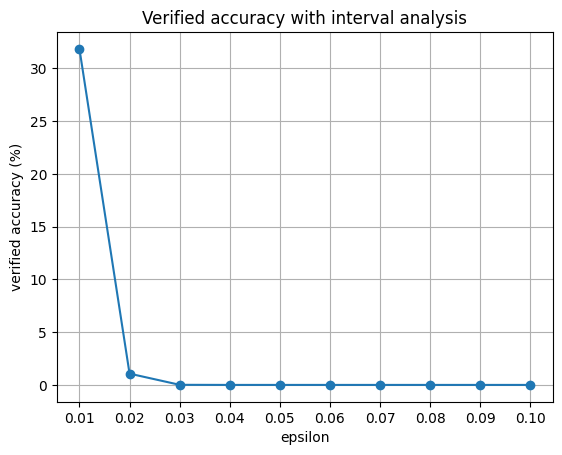

In [12]:
plt.plot(epsilons, ver_acc, marker='o')
plt.xlabel('epsilon')
plt.ylabel('verified accuracy (%)')
plt.title('Verified accuracy with interval analysis')
plt.xticks(epsilons)
plt.grid(True)
plt.show()

### Observations

The network gets 97.07% clean accuracy on the test set after 15 epochs.

| eps | 0.01 | 0.02 | 0.03 | 0.04 | 0.05 | 0.06 | 0.07 | 0.08 | 0.09 | 0.10 |
|---|---|---|---|---|---|---|---|---|---|---|
| verified accuracy | 31.85% | 1.07% | 0.01% | 0% | 0% | 0% | 0% | 0% | 0% | 0% |

Even at eps = 0.01 only about a third of the test images can be verified, and from eps = 0.04 on nothing is verified. The verified accuracy drops much faster than the clean accuracy would suggest.

I think the main reason is that interval analysis treats every neuron separately and loses the dependencies between them. In the first linear layer, the interval width gets multiplied by |W| and summed over all 784 pixels, so the hidden neurons already have wide intervals at small eps. Many hidden neurons then have l < 0 < u, and the ReLU just outputs [0, u]. The second layer adds up these worst cases again. Finally, the output layer computes f_y - f_j as l_y - u_j, which assumes f_y is at its minimum and f_j at its maximum at the same time, even though both depend on the same hidden neurons. The bound width grows roughly linearly with eps, and once it is larger than the margin f_y(x) - f_j(x), the image cannot be verified.

Interval analysis is sound but not complete, so "not verified" does not mean the image has an adversarial example. It only means the box bounds are too loose to prove it. The network was also trained normally, without any robustness objective, so its margins are not large relative to these bounds.